# Marketing A/B Test Analysis: Did the Ad Campaign Work?

**Tools:** Python (pandas, NumPy, SciPy, statsmodels), SQL (SQLite), Matplotlib

**Data:** [Marketing A/B Testing (Kaggle)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing), 588,101 users



## Executive summary

**Question:** did the ad campaign create extra conversions or would those customers have bought anyway?

- **The two groups are comparable.** Users in the ad and PSA groups saw almost the same number of ads (24.8 on average in both), so the comparison is fair.
- **The ads worked.** The ad group converted at **2.55%**, against **1.79%** for the PSA (control) group: a **43% relative lift** (95% CI 30% to 58%, p < 0.001).
- **But most conversions would have happened anyway.** Of the 14,423 conversions in the ad group, only about **4,343 (30%)** were created by the ads. Counting all of them would overstate the campaign more than three times.
- **Efficiency:** about **3,227 ad impressions** were needed for each extra conversion.
- **Next step:** the data has no cost or revenue, so profitability cannot be judged yet. Compare the value of the ~4,343 extra conversions with the campaign's cost before deciding to continue or expand it.


## 1. Business problem

**Context.** A marketing team spends budget on an online ad campaign. Looking only at how many ad viewers bought the product is misleading, because many of them would have bought anyway. To measure the true effect, the company ran an **A/B test**:

- **Treatment group ("ad"):** saw the company's ads.
- **Control group ("psa"):** saw a public service announcement in the exact same ad slot. They show us what happens without the ads.

Why show a public service announcement instead of nothing?
Because researchers want both groups to have the same experience of seeing something in the ad space.

The main difference is:
- One group sees the commercial advertisement.
- The other group does not see the commercial advertisement.

**The decision to support:** should the company keep paying for this campaign and how could it spend the budget better?

**Business questions**

1. Did the ads increase conversions and is the difference statistically significant? 
2. How many additional conversions did the ads generate (incremental conversions)?
3. How many ads were needed to generate each additional conversion?



**Success metric:** conversion rate = users who converted ÷ users in the group.

**Hypotheses** (significance level α = 0.05)

- **H₀:** the conversion rate is the same in the ad group and the PSA group.
- **H₁:** the conversion rate is different in the two groups.



## 2. The dataset

Each row is one user.


- `Unnamed: 0`  = dropped, row number, not useful 
- `user id` = Unique user identifier 
- `test group` = `ad` = saw the ads, `psa` = saw the public service announcement 
- `converted` = `True` if the user bought the product 
- `total ads` = Number of ads (or PSAs) the user saw 
- `most ads day` = Day of the week on which the user saw the most ads 
- `most ads hour` = Hour of the day (0 to 23) in which the user saw the most ads 

### 2.1 Setup

In [1]:
import math
import os
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

warnings.filterwarnings('ignore', category=FutureWarning)



AD_COLOR, PSA_COLOR, GREY, INK = 'tab:blue', 'red', 'lightgrey', 'black'

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

### 2.2 The dataset

In [2]:
raw = pd.read_csv('marketing_AB.csv')
print(f'Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}')
raw.head()

Rows: 588,101 | Columns: 7


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


588,101 rows and 7 columns. Every column is fully filled in. The first column is just a row counter and the column names contain spaces, so I clean both in the next section.


## 3. Data quality checks and cleaning

Before any analysis I check the things that could break an A/B test: missing values, duplicate users, users who appear in both groups and impossible values.

In [4]:
quality = pd.DataFrame({
    'Check': ['Missing values', 'Fully duplicated rows', 'Duplicated user ids',
              'Group labels', 'Converted values', 'Users with 0 or negative ads',
              'Hours outside 0-23', 'Day names'],
    'Result': [raw.isna().sum().sum(), raw.duplicated().sum(), raw['user id'].duplicated().sum(),
               ', '.join(sorted(raw['test group'].unique())), ', '.join(map(str, sorted(raw['converted'].unique()))),
               (raw['total ads'] <= 0).sum(), (~raw['most ads hour'].between(0, 23)).sum(),
               f"{raw['most ads day'].nunique()} unique, all valid: {set(raw['most ads day']) == set(DAYS)}"],
})
quality

,Check,Result
0,Missing values,0
1,Fully duplicated rows,0
2,Duplicated user ids,0
3,Group labels,"ad, psa"
4,Converted values,"False, True"
5,Users with 0 or negative ads,0
6,Hours outside 0-23,0
7,Day names,"7 unique, all valid: True"


In [5]:
df = raw.drop(columns='Unnamed: 0').copy()
df.columns = ['user_id', 'group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']
df['converted'] = df['converted'].astype(int)                                   # True/False -> 1/0
df['most_ads_day'] = pd.Categorical(df['most_ads_day'], categories=DAYS, ordered=True)

print(f'Clean dataset: {df.shape[0]:,} rows, {df.shape[1]} columns')
df.head()

Clean dataset: 588,101 rows, 6 columns


,user_id,group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


The data is clean. There are no missing values, no duplicated users (so nobody is in both groups) and no impossible values. The only cleaning needed was dropping the row counter, renaming the columns, turning `converted` into 1/0 and putting the days in calendar order. No rows were removed.


## 4. Exploratory data analysis (EDA)

### 4.1 How big are the two groups?

In [6]:
group_summary = df.groupby('group').agg(users=('user_id', 'size'), conversions=('converted', 'sum'))
group_summary['share_of_users_pct'] = group_summary['users'] / len(df) * 100
group_summary['conversion_rate_pct'] = group_summary['conversions'] / group_summary['users'] * 100
print(f"Overall conversion rate: {df['converted'].mean():.2%}")
group_summary

Overall conversion rate: 2.52%


,users,conversions,share_of_users_pct,conversion_rate_pct
group,,,,
ad,564577,14423,96.00,2.55
psa,23524,420,4.00,1.79


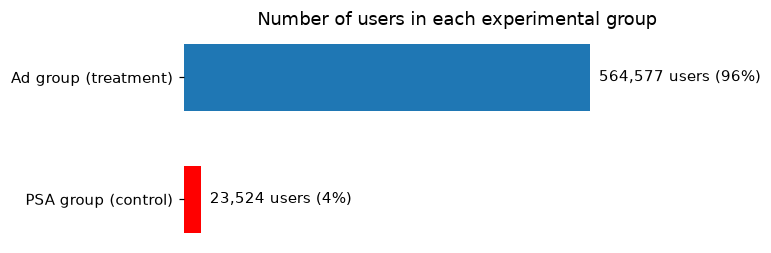

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.4))
bars = ax.barh(['PSA group (control)', 'Ad group (treatment)'], group_summary.loc[['psa', 'ad'], 'users'],
               color=[PSA_COLOR, AD_COLOR], height=0.55)
ax.bar_label(bars, labels=[f"{group_summary.loc[g, 'users']:,} users ({group_summary.loc[g, 'share_of_users_pct']:.0f}%)"
                           for g in ['psa', 'ad']], padding=6, color=INK)
ax.set_xlim(0, 760_000); ax.xaxis.set_visible(False); ax.grid(False); ax.spines[:].set_visible(False)
ax.set_title('Number of users in each experimental group')
plt.tight_layout(); plt.savefig('figures/01_group_sizes.png', bbox_inches='tight'); plt.show()

**Insight:** The group split is very uneven: 96% of users were assigned to the ad group and 4% to the PSA group. One possible business reason is that the company wanted to show its commercial ads to as many users as possible while maintaining a smaller control group for comparison.

The PSA group still contains 23,524 users, providing a substantial basis for comparison. However, because it is smaller than the ad group, its conversion rate is estimated with less precision. Conversion is also a relatively rare event: only 2.5% of all users converted.

### 4.2 How many ads did users see?

In [8]:
df['total_ads'].describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame().T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_ads,"588,101.00",24.82,43.72,1.00,4.00,13.00,27.00,57.00,88.00,202.00,"2,065.00"


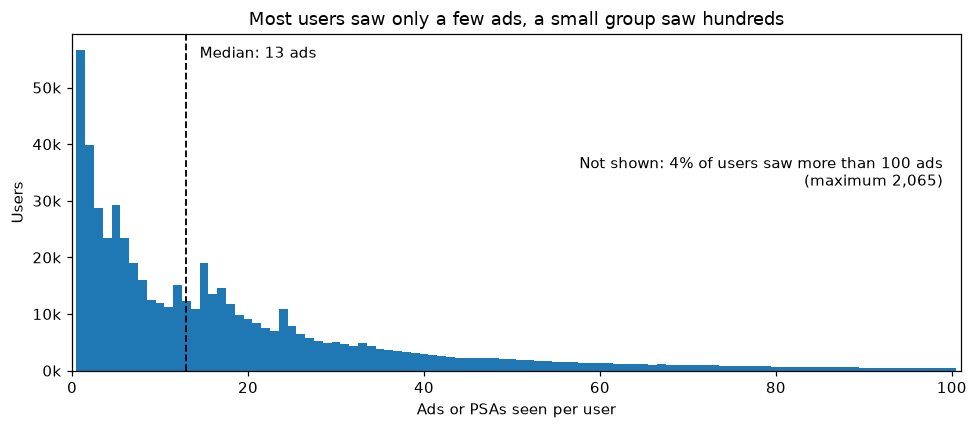

Users who saw more than 202 ads (1.0% of users) received 13% of all impressions.


In [9]:
median, p99 = df['total_ads'].median(), df['total_ads'].quantile(.99)
over_100 = (df['total_ads'] > 100).mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.loc[df['total_ads'] <= 100, 'total_ads'], bins=np.arange(0.5, 101.5, 1), color=AD_COLOR)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k'))
ax.axvline(median, color=INK, ls='--', lw=1.2)
ax.text(median + 1.5, ax.get_ylim()[1] * 0.93, f'Median: {median:.0f} ads', color=INK, fontsize=9.5)
ax.text(99, ax.get_ylim()[1] * 0.55, f"Not shown: {over_100:.0%} of users saw more than 100 ads\n(maximum {df['total_ads'].max():,})",
        color=INK, fontsize=9.5, ha='right')
ax.set_xlim(0, 101); ax.set_xlabel('Ads or PSAs seen per user'); ax.set_ylabel('Users'); ax.grid(axis='x', visible=False)
ax.set_title('Most users saw only a few ads, a small group saw hundreds')
plt.tight_layout(); plt.savefig('figures/02_ads_distribution.png', bbox_inches='tight'); plt.show()

heavy = df['total_ads'] > p99

print(
    f"Users who saw more than {p99:.0f} ads "
    f"({heavy.mean():.1%} of users) received "
    f"{df.loc[heavy, 'total_ads'].sum() / df['total_ads'].sum():.0%} "
    f"of all impressions."
)

**Insight:** The number of ads seen per user varies considerably. Half of all users saw 13 ads or fewer, while the average was 25. A small number of users saw much more advertising, with the highest exposure reaching 2,065 ads. The top 1% of users received 13% of all impressions.

The distribution is strongly right-skewed, meaning a small group of users accounts for a large share of total ad exposure. Therefore, the median and exposure groups are more useful than the average for describing typical user exposure. The histogram shows only users who saw up to 100 ads to keep the main distribution readable.

### 4.3 Do users who see more ads convert more often?

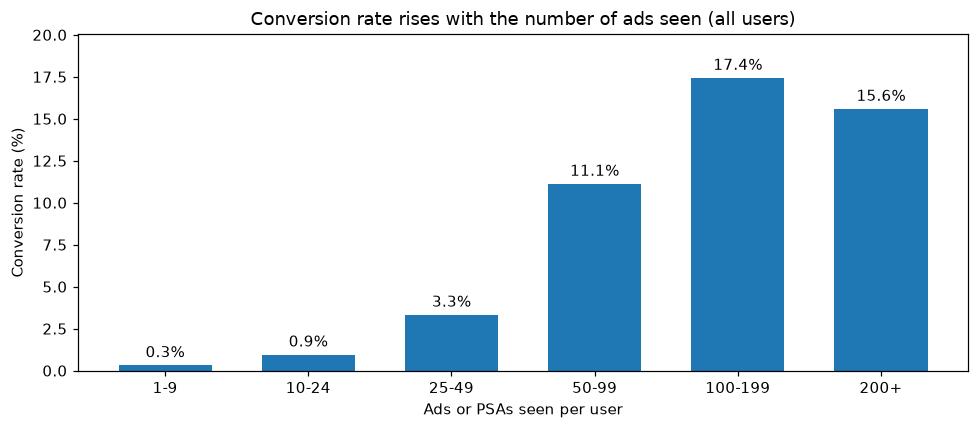

,users,conversion_rate_pct,share_of_users_pct
exposure,,,
1-9,248910,0.31,42.32
10-24,173223,0.95,29.45
25-49,94874,3.32,16.13
50-99,47625,11.12,8.10
100-199,17468,17.43,2.97
200+,6001,15.58,1.02


In [10]:
BANDS = ['1-9', '10-24', '25-49', '50-99', '100-199', '200+']
df['exposure'] = pd.cut(df['total_ads'], [0, 9, 24, 49, 99, 199, np.inf], labels=BANDS)

by_band = df.groupby('exposure', observed=True).agg(users=('user_id', 'size'), conversion_rate_pct=('converted', 'mean'))
by_band['conversion_rate_pct'] *= 100
by_band['share_of_users_pct'] = by_band['users'] / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(by_band.index, by_band['conversion_rate_pct'], color=AD_COLOR, width=0.65)
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in by_band['conversion_rate_pct']], padding=3, color=INK)
ax.set_ylim(0, by_band['conversion_rate_pct'].max() * 1.15)   # room above the tallest bar for its label
ax.set_xlabel('Ads or PSAs seen per user'); ax.set_ylabel('Conversion rate (%)'); ax.grid(axis='x', visible=False)
ax.set_title('Conversion rate rises with the number of ads seen (all users)')
plt.tight_layout(); plt.savefig('figures/03_conversion_by_exposure.png', bbox_inches='tight'); plt.show()
by_band

**Insight:** Conversion rates increase with the number of ads or PSAs seen, from approximately 0.3% among users who saw fewer than 10 ads to around 17% among users who saw 100–199 ads.

This is an observational relationship, not evidence that more advertising causes more purchases. Users who are more active may both see more ads and be more likely to purchase.

### 4.4 Are the two groups comparable?

An A/B test is only fair if the two groups are similar in everything except the ads. If, for example the ad group had seen far more ads or had been reached on different days, a difference in conversion could come from that instead of from the ads. I compare the two groups on all the other information in the data: how many ads users saw and the hour and day they saw the most ads. I leave out `converted`, because that is the result the test measures.

In [11]:
balance = df.groupby('group').agg(
    users=('user_id', 'size'),
    avg_ads_seen=('total_ads', 'mean'),
    median_ads_seen=('total_ads', 'median'),
    avg_most_ads_hour=('most_ads_hour', 'mean'),
)
display(balance.round(2))

day_share = pd.crosstab(df['most_ads_day'], df['group'], normalize='columns').mul(100).round(1)
day_share['difference_pts'] = (day_share['ad'] - day_share['psa']).round(1)
day_share.columns.name = None
print('Share of users by the day they saw the most ads (%):')
day_share

,users,avg_ads_seen,median_ads_seen,avg_most_ads_hour
group,,,,
ad,564577,24.82,13.00,14.48
psa,23524,24.76,12.00,14.30


Share of users by the day they saw the most ads (%):


,ad,psa,difference_pts
most_ads_day,,,
Monday,14.80,14.90,-0.10
Tuesday,13.20,12.40,0.80
Wednesday,13.70,14.80,-1.10
Thursday,14.00,16.60,-2.60
Friday,15.70,16.20,-0.50
Saturday,14.00,12.10,1.90
Sunday,14.60,13.00,1.60


**Insight:** the groups look comparable. Users in both groups saw almost the same number of ads (**24.8 on average** in each, median 13 against 12) and were most exposed at a similar time of day. The day on which users saw the most ads differs by at most **2.6 percentage points** between the groups, a small difference. Nothing here suggests the groups were set up differently, which supports reading the conversion gap in section 5 as an effect of the ads. The dataset does not describe how users were assigned, so this check supports the comparison but cannot fully prove the randomisation (see Limitations).


## 5. A/B test: did the ads increase conversions?

### 5.1 Conversion rate per group (SQL)

I load the table into an in-memory SQLite database to show the same summary a business analyst would pull from a data warehouse.

In [12]:
conn = sqlite3.connect(':memory:')
df.drop(columns='exposure').astype({'most_ads_day': str}).to_sql('users', conn, index=False)

results = pd.read_sql_query('''
SELECT  "group",
        COUNT(*)                         AS users,
        SUM(converted)                   AS conversions,
        ROUND(100.0 * AVG(converted), 2) AS conversion_rate_pct
FROM    users
GROUP BY "group"
''', conn).set_index('group')
results

,users,conversions,conversion_rate_pct
group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


### 5.2 Statistical test

The outcome is yes/no (converted or not) and the two groups are independent and large, so the right tool is a **two-proportion z-test**. I also run a **chi-square test** as a cross-check and compute a **95% confidence interval** for the difference, because the size of the effect matters more to the business than the p-value.

In [13]:
ad_n, ad_c = int(results.loc['ad', 'users']), int(results.loc['ad', 'conversions'])
psa_n, psa_c = int(results.loc['psa', 'users']), int(results.loc['psa', 'conversions'])
ad_rate, psa_rate = ad_c / ad_n, psa_c / psa_n

# Two-proportion z-test and chi-square test
z_stat, p_value = proportions_ztest([ad_c, psa_c], [ad_n, psa_n])
chi2, p_chi2, _, _ = stats.chi2_contingency(pd.crosstab(df['group'], df['converted']), correction=False)

# 95% confidence interval for the absolute difference
difference = ad_rate - psa_rate
se = math.sqrt(ad_rate * (1 - ad_rate) / ad_n + psa_rate * (1 - psa_rate) / psa_n)
margin = 1.96 * se
ci_low, ci_high = difference - margin, difference + margin

# 95% confidence interval for the relative lift (on the log scale)
ratio = ad_rate / psa_rate
se_log = math.sqrt((1 - ad_rate) / ad_c + (1 - psa_rate) / psa_c)
rel_low, rel_high = math.exp(math.log(ratio) - 1.96 * se_log) - 1, math.exp(math.log(ratio) + 1.96 * se_log) - 1

print(f'Ad group conversion rate:   {ad_rate:.2%}')
print(f'PSA group conversion rate:  {psa_rate:.2%}')
print(f'Absolute difference:        {difference * 100:.2f} percentage points (95% CI {ci_low * 100:.2f} to {ci_high * 100:.2f})')
print(f'Relative lift:              {ratio - 1:.0%} (95% CI {rel_low:.0%} to {rel_high:.0%})')
print(f'z-test:                     z = {z_stat:.2f}, p = {p_value:.1e}')
print(f'Chi-square test:            chi2 = {chi2:.1f}, p = {p_chi2:.1e}')
print(f"Decision at alpha = 0.05:   {'reject H0, the rates differ' if p_value < 0.05 else 'cannot reject H0'}")

Ad group conversion rate:   2.55%
PSA group conversion rate:  1.79%
Absolute difference:        0.77 percentage points (95% CI 0.60 to 0.94)
Relative lift:              43% (95% CI 30% to 58%)
z-test:                     z = 7.37, p = 1.7e-13
Chi-square test:            chi2 = 54.3, p = 1.7e-13
Decision at alpha = 0.05:   reject H0, the rates differ


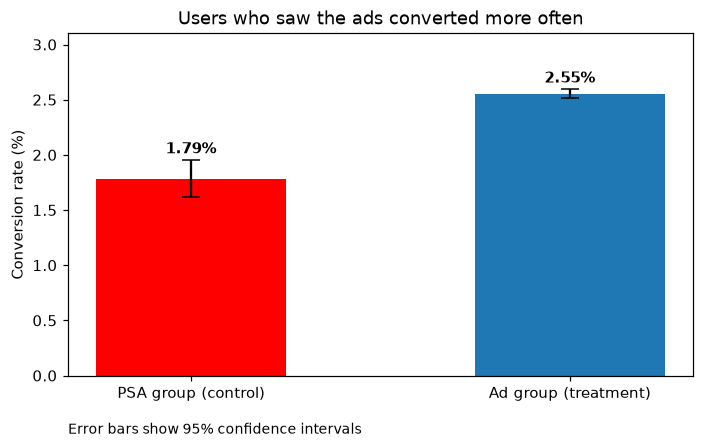

In [14]:
rates = np.array([psa_rate, ad_rate]) * 100
errors = 196 * np.sqrt([psa_rate * (1 - psa_rate) / psa_n, ad_rate * (1 - ad_rate) / ad_n])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(['PSA group (control)', 'Ad group (treatment)'], rates, yerr=errors, capsize=6,
              color=[PSA_COLOR, AD_COLOR], ecolor=INK, width=0.5)
for i, (r, e) in enumerate(zip(rates, errors)):
    ax.text(i, r + e + 0.06, f'{r:.2f}%', ha='center', fontweight='bold')
ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 3.1); ax.grid(axis='x', visible=False)
ax.set_title('Users who saw the ads converted more often')
ax.text(0, -0.17, 'Error bars show 95% confidence intervals', transform=ax.transAxes, color=INK, fontsize=9)
plt.tight_layout(); plt.savefig('figures/04_conversion_rate_ab.png', bbox_inches='tight'); plt.show()

**Insight:** yes, the ads worked.

- The ad group converted at **2.55%** and the PSA group at **1.79%**.
- The difference is **0.77 percentage points** (95% CI 0.60 to 0.94), a **43% relative lift** (95% CI 30% to 58%).
- The p-value is far below 0.05 in both tests (z = 7.37), so I reject H₀. A gap this large is extremely unlikely to be chance.
- The confidence intervals of the two groups do not overlap and the PSA group's interval is wider because that group is smaller.

## 6. Business impact: what did the ads really add?

### 6.1 Incremental conversions

The ad group had 14,423 conversions but not all of them were caused by ads. The PSA group shows how many would have happened anyway:

 **extra conversions = ad group conversions − (PSA conversion rate × ad group users)**

Total conversions in the ad group:  14,423
Would likely have happened anyway:  10,080 (70%)
Extra conversions from the ads:     4,343 (30%), 95% CI 3,360 to 5,326


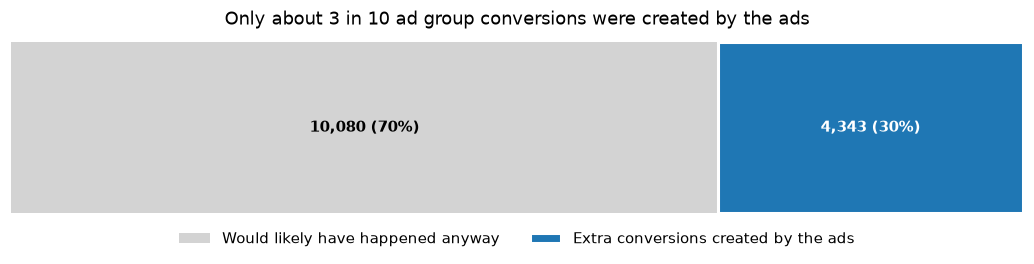

In [15]:
anyway = psa_rate * ad_n
extra = ad_c - anyway
extra_low, extra_high = ci_low * ad_n, ci_high * ad_n

print(f'Total conversions in the ad group:  {ad_c:,.0f}')
print(f'Would likely have happened anyway:  {anyway:,.0f} ({anyway / ad_c:.0%})')
print(f'Extra conversions from the ads:     {extra:,.0f} ({extra / ad_c:.0%}), 95% CI {extra_low:,.0f} to {extra_high:,.0f}')

fig, ax = plt.subplots(figsize=(9.5, 2.5))
ax.barh([''], [anyway], color=GREY, height=0.6, label='Would likely have happened anyway')
ax.barh([''], [extra], left=[anyway], color=AD_COLOR, height=0.6, edgecolor='white', linewidth=2, label='Extra conversions created by the ads')
ax.text(anyway / 2, 0, f'{anyway:,.0f} ({anyway / ad_c:.0%})', ha='center', va='center', fontweight='bold')
ax.text(anyway + extra / 2, 0, f'{extra:,.0f} ({extra / ad_c:.0%})', ha='center', va='center', fontweight='bold', color='white')
ax.set_xlim(0, ad_c); ax.grid(False); ax.xaxis.set_visible(False); ax.spines[:].set_visible(False); ax.tick_params(left=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)
ax.set_title('Only about 3 in 10 ad group conversions were created by the ads')
plt.tight_layout(); plt.savefig('figures/05_incremental_conversions.png', bbox_inches='tight'); plt.show()

**Insight:** counting all 14,423 conversions would overstate the campaign by more than three times. About 10,080 (70%) would likely have happened anyway. The ads created about **4,343 extra conversions** (95% CI 3,360 to 5,326). This incremental number is the one the campaign should be judged on.

### 6.2 How much advertising does one extra conversion take?


The dataset does not contain advertising cost or revenue data, so I cannot calculate campaign profit or ROI. I can estimate how many ad impressions were associated with each additional conversion.

In [16]:
ads_shown = df.loc[df['group'] == 'ad', 'total_ads'].sum()
ads_per_extra = ads_shown / extra

print(f'Ad impressions shown: {ads_shown:,.0f}')
print(f'Impressions per additional conversion: {ads_per_extra:,.0f}')

Ad impressions shown: 14,014,701
Impressions per additional conversion: 3,227


Approximately 3,227 ad impressions were associated with each additional conversion. Actual campaign cost and ROI cannot be calculated without advertising cost and revenue data.



## 7. Outputs

In [17]:
summary = pd.DataFrame({
    'metric': [
        'ad_users',
        'psa_users',
        'ad_conversion_rate_pct',
        'psa_conversion_rate_pct',
        'lift_points',
        'lift_ci_low',
        'lift_ci_high',
        'relative_lift_pct',
        'p_value',
        'extra_conversions',
        'ads_per_extra_conversion'
    ],
    'value': [
        ad_n,
        psa_n,
        ad_rate * 100,
        psa_rate * 100,
        difference * 100,
        ci_low * 100,
        ci_high * 100,
        (ratio - 1) * 100,
        p_value,
        extra,
        ads_per_extra
    ]
})

summary.to_csv('outputs/ab_test_summary.csv', index=False)

conn.close()

print('Summary table saved successfully.')

Summary table saved successfully.



## 8. Conclusions and recommendations

### Answers to the business questions

| # | Question | Answer |
|---|---|---|
| 1 | Did the ads increase conversions? | **Yes.** The ad group converted at 2.55%, compared with 1.79% for the PSA group. The difference was 0.77 percentage points (95% CI: 0.60–0.94), representing a 43% relative lift (p < 0.001). |
| 2 | How many additional conversions were estimated? | Approximately 4,343 (95% CI: 3,360–5,326), equivalent to around 30% of the ad group's conversions. |
| 3 | How much advertising was required per additional conversion? | Approximately 3,227 ad impressions per additional conversion. |

### Recommendations

- Evaluate campaign profitability. Compare the value of the estimated additional conversions with actual advertising costs before deciding whether to continue or expand the campaign.

- Measure incremental conversions. Do not attribute every purchase made by someone who saw an ad to the campaign. Use the difference between the ad and control groups to estimate the additional conversions associated with advertising.

- Maintain a control group. Continue using a control group exposed to public service announcements (PSAs) to measure the performance of future advertising campaigns.

- Improve future experiments. Document the randomisation process and collect advertising cost, revenue and conversion timing data. This will support more reliable measurement of campaign effectiveness and return on investment.


## 9. Limitations and next steps

**Limitations**

- **No cost or revenue data:** The analysis estimates additional conversions but cannot calculate campaign profit or return on investment (ROI).
- **Unknown randomisation process:** The dataset does not explain how users were assigned to the ad and PSA groups, so the experiment design cannot be independently verified.
- **Small control group:** The PSA group represents only 4% of users. This makes its conversion-rate estimate less precise.
- **Missing context:** The dataset does not specify the product, the exact definition of a conversion or the campaign period.
- **Ads vs PSA:** The control group saw public service announcements rather than receiving no advertising.
- **Public dataset:** The original experiment setup and data collection process cannot be independently confirmed.



**Next steps**

1. Collect financial data: Record advertising costs and revenue per conversion to calculate campaign ROI.
2. Document the experiment design: Record how users are assigned to groups and the planned group sizes.
3. Increase the control group: Consider using a larger control group in future experiments to improve the precision of conversion estimates.
4. Record conversion timestamps: Understand how long after ad exposure users make a purchase.
